# EDA of Stellar Classification Dataset
The EDA is done within the requirements of the said problem statement,
Stated as,<br>
>'How much can the number of astronomical observations be reduced while maintaining accurate classification of stars, galaxies, and quasars using machine learning?'

The original dataset contains 1000000 x 18
>**Note:** This is not a basic classification task but rather research for an optimized approach of whether the given amount of columns is actually necessary or not.
>
> The results will eventually help understand if the resources used to record the observation can be used much efficiently and focused on some observations and still give the best results?

In [1]:
# Necessary imports for the given task
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the data set
df = pd.read_csv("Data/star_classification.csv")
df.head()

,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
0,1.237661e+18,135.689107,32.494632,23.87882,22.27530,20.39501,19.16573,18.79371,3606,301,2,79,6.543777e+18,GALAXY,0.634794,5812,56354,171
1,1.237665e+18,144.826101,31.274185,24.77759,22.83188,22.58444,21.16812,21.61427,4518,301,5,119,1.176014e+19,GALAXY,0.779136,10445,58158,427
2,1.237661e+18,142.188790,35.582444,25.26307,22.66389,20.60976,19.34857,18.94827,3606,301,2,120,5.152200e+18,GALAXY,0.644195,4576,55592,299
3,1.237663e+18,338.741038,-0.402828,22.13682,23.77656,21.61162,20.50454,19.25010,4192,301,3,214,1.030107e+19,GALAXY,0.932346,9149,58039,775
4,1.237680e+18,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,8102,301,3,137,6.891865e+18,GALAXY,0.116123,6121,56187,842


In [3]:
print(df.info())
print()
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 18 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   obj_ID       100000 non-null  float64
 1   alpha        100000 non-null  float64
 2   delta        100000 non-null  float64
 3   u            100000 non-null  float64
 4   g            100000 non-null  float64
 5   r            100000 non-null  float64
 6   i            100000 non-null  float64
 7   z            100000 non-null  float64
 8   run_ID       100000 non-null  int64  
 9   rerun_ID     100000 non-null  int64  
 10  cam_col      100000 non-null  int64  
 11  field_ID     100000 non-null  int64  
 12  spec_obj_ID  100000 non-null  float64
 13  class        100000 non-null  str    
 14  redshift     100000 non-null  float64
 15  plate        100000 non-null  int64  
 16  MJD          100000 non-null  int64  
 17  fiber_ID     100000 non-null  int64  
dtypes: float64(10), int64(7), str(1)
mem

# Observation Currently
> <b>float64:</b> obj_ID, alpha, delta, u, g, r, i, z, spec_obj_ID, redshift
>
> <b>int64:</b> run_ID, rerun_ID, cam_col, field_ID, plate, MJD, fibre_ID
>
> <b>str:</b> class (GALAXY, QSO, STAR)

In [4]:
print("Missing values: ")
print(df.isnull().sum())
print()
print("Duplicate rows: ",df.duplicated().sum())

Missing values: 
obj_ID         0
alpha          0
delta          0
u              0
g              0
r              0
i              0
z              0
run_ID         0
rerun_ID       0
cam_col        0
field_ID       0
spec_obj_ID    0
class          0
redshift       0
plate          0
MJD            0
fiber_ID       0
dtype: int64

Duplicate rows:  0


class
GALAXY    59.445
STAR      21.594
QSO       18.961
Name: proportion, dtype: float64


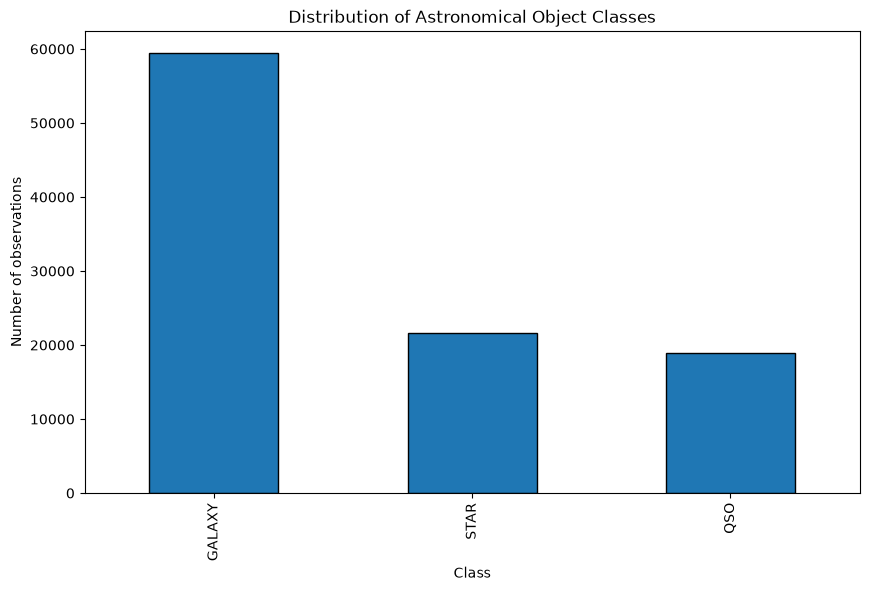

In [5]:
print(df['class'].value_counts(normalize=True) * 100)
df['class'].value_counts().plot(kind='bar',edgecolor='black', figsize=(10, 6))
plt.xlabel('Class')
plt.ylabel('Number of observations')
plt.title('Distribution of Astronomical Object Classes')
plt.show()

# Observation Currently

> Heavy class imbalance can be observed in the data set.
>
> Where Galaxy holds more than 50% of the classifications followed by Star and QSO.
>
> This can be either solved by oversampling or undersampling
>
> Or we may use a tree based model since they handle class imabalances inherently.

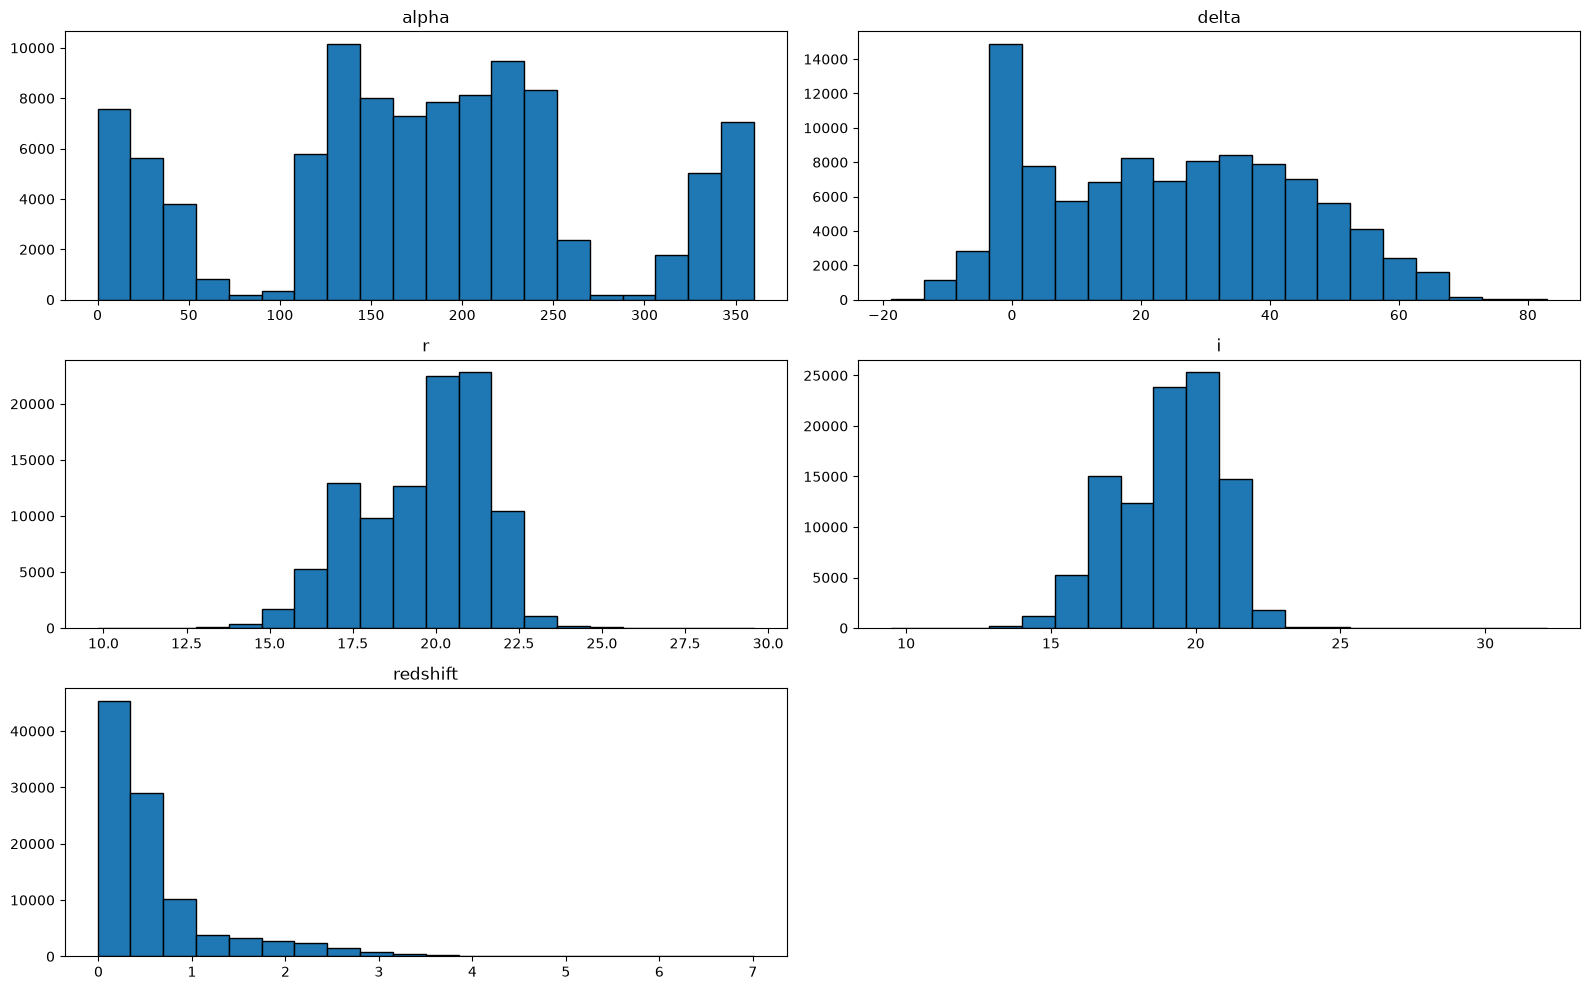

In [6]:
numeric_cols = ['alpha', 'delta', 'r', 'i', 'redshift']
df[numeric_cols].hist(figsize=(16, 10), edgecolor='black', bins=20, grid=False)
plt.tight_layout()
plt.show()

In [7]:
cols = {
    "u": "Ultraviolet",
    "g": "Green",
    "z": "Infrared",
    "r": "Red",
    "i": "Near Infrared"   
}

keys = list(cols.keys())
df[keys] = df[keys].replace(-9999, np.nan)

# Observation Currently
<p> 
Outlier in u, g, z (-9999) may be replaced by appropriate method after finding the distribution of data 
but currently may be swapped with a nan.
</p>

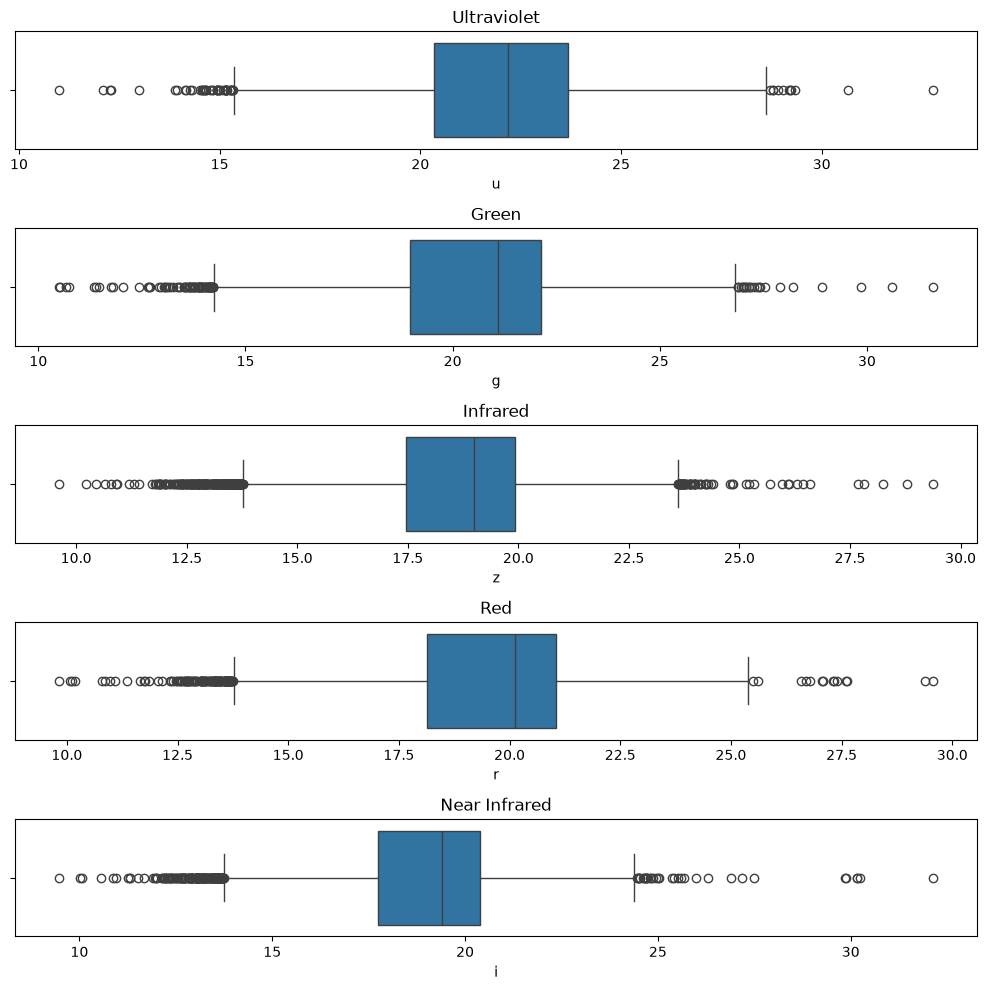

In [8]:
fig, axes = plt.subplots(5,1,figsize=(10,10))

for i, col in enumerate(cols):
    sns.boxplot(x = df[col], ax = axes[i])
    axes[i].set_title(cols[col])
    
plt.tight_layout()
plt.show()

In [9]:
# Mean and Median of each of the columns currently being plotted
mean_values = df[keys].mean()
median_values = df[keys].median()
print("Mean Values \t Median Values")
for col in keys:
    print(f"{col}: {mean_values[col]:.2f} {(('   >   ') if mean_values[col] > median_values[col] else ('   <   '))} {median_values[col]:.2f}")

Mean Values 	 Median Values
u: 22.08    <    22.18
g: 20.63    <    21.10
z: 18.77    <    19.00
r: 19.65    <    20.13
i: 19.08    <    19.41


In [10]:
print(f"GALAXY: {len(df[df["class"]=="GALAXY"])}")
print(f"STAR: {len(df[df["class"]=="STAR"])}")
print(f"QSO: {len(df[df["class"]=="QSO"])}")

GALAXY: 59445
STAR: 21594
QSO: 18961
